In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# read the csv file through pandas
df=pd.read_csv(r"C:\Users\LENOVO\Downloads\Zomato Dataset.csv\Zomato Dataset.csv")

In [3]:
# show only the 5 records from top
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [4]:
# information about the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  str    
 1   Delivery_person_ID           45584 non-null  str    
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  str    
 9   Time_Orderd                  43853 non-null  str    
 10  Time_Order_picked            45584 non-null  str    
 11  Weather_conditions           44968 non-null  str    
 12  Road_traffic_density         44983 non-null  str    
 13  Vehicle_condition          

In [5]:
# statistical details about the numerical values
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken (min)
count,43730.000000,43676.000000,45584.000000,45584.000000,45584.000000,45584.000000,45584.000000,44591.000000,45584.000000
mean,29.566911,4.633774,17.017948,70.229684,17.465480,70.844161,1.023385,0.744635,26.293963
std,5.815064,0.334744,8.185674,22.885575,7.335562,21.120578,0.839055,0.572510,9.384298
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.551440,75.897963,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [6]:
# statistical details about the categorical values
df.describe(include='object')

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12972\2908118092.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,ID,Delivery_person_ID,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Type_of_order,Type_of_vehicle,Festival,City
count,45584,45584,45584,43853,45584,44968,44983,45584,45584,45356,44384
unique,45584,1320,44,176,193,6,4,4,4,2,3
top,0xcdcd,JAPRES11DEL02,15-03-2022,21:55,21:30,Fog,Low,Snack,motorcycle,No,Metropolitian
freq,1,67,1192,461,495,7653,15476,11530,26429,44460,34087


In [7]:
# check the total null values for each columns
df.isnull().sum()

ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weather_conditions              616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken (min)                  0
dtype: int64

In [8]:
# check which columns has the highest percentage of the missing values
missing = df.isnull().sum()
missing_percentage = (missing / len(df)) * 100
pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage
}).sort_values("Missing Percentage", ascending=False)

,Missing Values,Missing Percentage
Delivery_person_Ratings,1908,4.185679
Delivery_person_Age,1854,4.067217
Time_Orderd,1731,3.797385
City,1200,2.632503
multiple_deliveries,993,2.178396
Weather_conditions,616,1.351351
Road_traffic_density,601,1.318445
Festival,228,0.500176
ID,0,0.000000
Delivery_person_ID,0,0.000000


In [9]:
 # for col in df.columns:
 #    if df[col].isnull().sum() > 0:
 #        print("\n", col)
 #        print(df[col].unique()[:20])

In [10]:
# to check any duplicates in the data
df.duplicated().sum()

np.int64(0)

In [11]:
# to check the duplicates in the ID columns
df['ID'].duplicated().sum()

np.int64(0)

In [12]:
# statistical information about the categorical data which has higher null values
df[['Delivery_person_Age',
    'Delivery_person_Ratings',
    'multiple_deliveries',
    'Vehicle_condition',
    'Time_taken (min)']].describe()

,Delivery_person_Age,Delivery_person_Ratings,multiple_deliveries,Vehicle_condition,Time_taken (min)
count,43730.000000,43676.000000,44591.000000,45584.000000,45584.000000
mean,29.566911,4.633774,0.744635,1.023385,26.293963
std,5.815064,0.334744,0.572510,0.839055,9.384298
min,15.000000,1.000000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,1.000000,1.000000,26.000000
75%,35.000000,4.900000,1.000000,2.000000,32.000000
max,50.000000,6.000000,3.000000,3.000000,54.000000


In [13]:
# how many Delivery person is rated more than 5
df[df['Delivery_person_Ratings']>5]['Delivery_person_Ratings'].value_counts()

Delivery_person_Ratings
6.0    53
Name: count, dtype: int64

In [14]:
# show the top 20 records of data with more than 5 rating
df[df['Delivery_person_Ratings'] > 5][
    ['Delivery_person_ID', 'Delivery_person_Age',
     'Delivery_person_Ratings', 'City', 'Time_taken (min)']
].head(20)

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,City,Time_taken (min)
3577,BANGRES05DEL01,50.0,6.0,Urban,25
4705,HYDRES17DEL01,50.0,6.0,Metropolitian,27
5160,JAPRES08DEL01,50.0,6.0,Metropolitian,20
5353,BANGRES19DEL01,50.0,6.0,Metropolitian,18
5642,AGRRES13DEL02,50.0,6.0,Metropolitian,20
6385,JAPRES06DEL02,50.0,6.0,Urban,20
7022,MYSRES15DEL02,50.0,6.0,Metropolitian,14
7672,VADRES09DEL01,50.0,6.0,Metropolitian,22
9490,BANGRES010DEL01,50.0,6.0,Urban,17
9526,RANCHIRES13DEL01,50.0,6.0,Metropolitian,32


In [15]:
#number of people with each age 
df['Delivery_person_Age'].value_counts().sort_index()

Delivery_person_Age
15.0      38
20.0    2136
21.0    2153
22.0    2194
23.0    2086
24.0    2210
25.0    2174
26.0    2159
27.0    2150
28.0    2179
29.0    2191
30.0    2226
31.0    2120
32.0    2201
33.0    2186
34.0    2165
35.0    2261
36.0    2260
37.0    2226
38.0    2218
39.0    2144
50.0      53
Name: count, dtype: int64

In [16]:

df[df['Delivery_person_Age'] == 15][
    ['Delivery_person_ID',
     'Delivery_person_Age',
     'Delivery_person_Ratings',
     'City',
     'Time_taken (min)']
]

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,City,Time_taken (min)
2378,JAPRES15DEL03,15.0,1.0,Urban,15
2896,INDORES010DEL03,15.0,1.0,Metropolitian,29
2942,SURRES17DEL03,15.0,1.0,Metropolitian,20
5893,CHENRES15DEL03,15.0,1.0,Metropolitian,25
9147,BANGRES05DEL01,15.0,1.0,Metropolitian,34
10891,MUMRES14DEL02,15.0,1.0,Metropolitian,39
11116,SURRES12DEL01,15.0,1.0,Urban,27
12084,INDORES03DEL02,15.0,1.0,Metropolitian,28
15115,RANCHIRES02DEL01,15.0,1.0,Metropolitian,21
15918,CHENRES08DEL02,15.0,1.0,Metropolitian,17


In [17]:
# Delivery person with age of 15 and 50 and also rating with more than 5 is made nan
# because deleting these rows will cost us some import details that lies in the other columns
df.loc[df['Delivery_person_Age'].isin([15, 50]), 'Delivery_person_Age'] = np.nan

In [18]:
df.loc[df['Delivery_person_Ratings'] > 5, 'Delivery_person_Ratings'] = np.nan

In [19]:
# now the total numbers of our none values in both columns
df[['Delivery_person_Age', 'Delivery_person_Ratings']].isna().sum()

Delivery_person_Age        1945
Delivery_person_Ratings    1961
dtype: int64

In [20]:
# columns with the missing values it holding
df.isna().sum()

ID                                0
Delivery_person_ID                0
Delivery_person_Age            1945
Delivery_person_Ratings        1961
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weather_conditions              616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken (min)                  0
dtype: int64

In [21]:
# columns with percentage of missing values
df.isna().mean().mul(100).round(2)

ID                             0.00
Delivery_person_ID             0.00
Delivery_person_Age            4.27
Delivery_person_Ratings        4.30
Restaurant_latitude            0.00
Restaurant_longitude           0.00
Delivery_location_latitude     0.00
Delivery_location_longitude    0.00
Order_Date                     0.00
Time_Orderd                    3.80
Time_Order_picked              0.00
Weather_conditions             1.35
Road_traffic_density           1.32
Vehicle_condition              0.00
Type_of_order                  0.00
Type_of_vehicle                0.00
multiple_deliveries            2.18
Festival                       0.50
City                           2.63
Time_taken (min)               0.00
dtype: float64

In [22]:
# print the median of two columns
print("Age median:", df['Delivery_person_Age'].median())
print("Rating median:", df['Delivery_person_Ratings'].median())

Age median: 30.0
Rating median: 4.7


In [23]:
# fill the missing values of age with the age median
df['Delivery_person_Age']=df['Delivery_person_Age'].fillna(df['Delivery_person_Age'].median())

In [24]:
# fill the missing values of rating with median rating
df['Delivery_person_Ratings']=df['Delivery_person_Ratings'].fillna(df['Delivery_person_Ratings'].median())

In [25]:
# No of observations for each type 
for col in ['Weather_conditions',
            'Road_traffic_density',
            'Festival',
            'City']:
    print("\n", col)
    print(df[col].value_counts())


 Weather_conditions
Weather_conditions
Fog           7653
Stormy        7584
Cloudy        7533
Sandstorms    7494
Windy         7422
Sunny         7282
Name: count, dtype: int64

 Road_traffic_density
Road_traffic_density
Low       15476
Jam       14139
Medium    10945
High       4423
Name: count, dtype: int64

 Festival
Festival
No     44460
Yes      896
Name: count, dtype: int64

 City
City
Metropolitian    34087
Urban            10133
Semi-Urban         164
Name: count, dtype: int64


In [26]:
# fillig missing values with unknown
categorical_cols = [
    'Weather_conditions',
    'Road_traffic_density',
    'Festival',
    'City'
]

for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')

In [27]:
df[categorical_cols].isna().sum()

Weather_conditions      0
Road_traffic_density    0
Festival                0
City                    0
dtype: int64

In [28]:
# df['multiple_deliveries'].value_counts().sort_index()
df['multiple_deliveries'].mode()

0    1.0
Name: multiple_deliveries, dtype: float64

In [29]:
# filling the null values of multiple deliveries columns with Mode value
df['multiple_deliveries']=df['multiple_deliveries'].fillna(df['multiple_deliveries'].mode()[0])

In [30]:
df['Time_Orderd'].value_counts().head(20)

Time_Orderd
21:55          461
17:55          456
0.833333333    449
22:20          448
21:35          446
19:50          444
21:15          442
22:45          438
21:20          437
18:35          436
19:55          436
21:25          435
18:10          435
17:35          435
22:10          434
23:30          434
17:25          431
17:40          431
1              430
23:25          429
Name: count, dtype: int64

In [31]:
df['Time_Orderd'].map(type).value_counts()

Time_Orderd
<class 'str'>      43853
<class 'float'>     1731
Name: count, dtype: int64

In [32]:
df['Time_Orderd'].unique()[:30]

<StringArray>
[      '21:55',       '14:55',       '17:30',       '09:20',       '19:50',
       '20:25',       '20:30',       '20:40',       '21:15',       '20:20',
       '22:30',       '08:15',       '19:30',       '12:25',       '18:35',
       '20:35',       '23:20',       '21:20',       '23:35',       '22:35',
       '23:25',       '13:35',       '21:35',       '18:55',       '14:15',
 '0.458333333',       '09:45',       '08:40', '0.958333333',       '17:25']
Length: 30, dtype: str

In [33]:

def convert_time(x):
    if pd.isna(x):
        return None

    x = str(x)

    if ':' in x:
        h, m = map(int, x.split(':'))
        return h * 60 + m

    # Decimal/Excel time
    return round(float(x) * 24 * 60) % 1440


df['Order_Time_Minutes'] = df['Time_Orderd'].apply(convert_time)

In [34]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),Order_Time_Minutes
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,...,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,1315.0
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,...,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,895.0
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,...,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,1050.0
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,...,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,560.0
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,...,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,1190.0


In [35]:
df['Order_Time_Minutes'].median()

np.float64(1155.0)

In [36]:
df['Order_Time_Minutes'] = df['Order_Time_Minutes'].fillna(
    df['Order_Time_Minutes'].median()
)

In [37]:
df['Order_Time_Minutes'].isna().sum()

np.int64(0)

In [38]:
df.isna().sum()

ID                                0
Delivery_person_ID                0
Delivery_person_Age               0
Delivery_person_Ratings           0
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weather_conditions                0
Road_traffic_density              0
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries               0
Festival                          0
City                              0
Time_taken (min)                  0
Order_Time_Minutes                0
dtype: int64

In [39]:
df.drop('Time_Orderd', axis=1, inplace=True)

In [40]:
df.isna().sum()

ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Order_picked              0
Weather_conditions             0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken (min)               0
Order_Time_Minutes             0
dtype: int64

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  str    
 1   Delivery_person_ID           45584 non-null  str    
 2   Delivery_person_Age          45584 non-null  float64
 3   Delivery_person_Ratings      45584 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  str    
 9   Time_Order_picked            45584 non-null  str    
 10  Weather_conditions           45584 non-null  str    
 11  Road_traffic_density         45584 non-null  str    
 12  Vehicle_condition            45584 non-null  int64  
 13  Type_of_order              

In [42]:
df['Order_Date'].unique()[:50]

<StringArray>
['12-02-2022', '13-02-2022', '04-03-2022', '14-02-2022', '02-04-2022',
 '01-03-2022', '16-03-2022', '20-03-2022', '15-02-2022', '10-03-2022',
 '11-03-2022', '27-03-2022', '26-03-2022', '05-04-2022', '12-03-2022',
 '01-04-2022', '05-03-2022', '11-02-2022', '08-03-2022', '03-04-2022',
 '30-03-2022', '28-03-2022', '18-03-2022', '14-03-2022', '06-04-2022',
 '04-04-2022', '24-03-2022', '19-03-2022', '09-03-2022', '25-03-2022',
 '02-03-2022', '13-03-2022', '29-03-2022', '31-03-2022', '17-03-2022',
 '07-03-2022', '15-03-2022', '16-02-2022', '03-03-2022', '18-02-2022',
 '23-03-2022', '17-02-2022', '06-03-2022', '21-03-2022']
Length: 44, dtype: str

In [43]:
df['Order_Date'] = pd.to_datetime(
    df['Order_Date'],
    format='%d-%m-%Y'
)

In [44]:
df['Order_Date'].dtype

dtype('<M8[us]')

In [45]:
df['Order_Day'] = df['Order_Date'].dt.day
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_DayOfWeek'] = df['Order_Date'].dt.dayofweek

In [46]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Order_picked,...,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),Order_Time_Minutes,Order_Day,Order_Month,Order_DayOfWeek
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,2022-02-12,22:10,...,Snack,motorcycle,3.0,No,Metropolitian,46,1315.0,12,2,5
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,2022-02-13,15:05,...,Meal,motorcycle,1.0,No,Metropolitian,23,895.0,13,2,6
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,2022-03-04,17:40,...,Drinks,scooter,1.0,No,Metropolitian,21,1050.0,4,3,4
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,2022-02-13,09:30,...,Buffet,motorcycle,0.0,No,Metropolitian,20,560.0,13,2,6
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,2022-02-14,20:05,...,Snack,scooter,1.0,No,Metropolitian,41,1190.0,14,2,0


In [47]:
df[['Order_Date', 'Order_Day', 'Order_Month', 'Order_DayOfWeek']].head(10)

,Order_Date,Order_Day,Order_Month,Order_DayOfWeek
0,2022-02-12,12,2,5
1,2022-02-13,13,2,6
2,2022-03-04,4,3,4
3,2022-02-13,13,2,6
4,2022-02-14,14,2,0
5,2022-04-02,2,4,5
6,2022-03-01,1,3,1
7,2022-03-16,16,3,2
8,2022-03-20,20,3,6
9,2022-02-15,15,2,1


In [48]:
df.drop(['Order_Date', 'Order_Day'], axis=1, inplace=True)

In [49]:
df.shape

(45584, 21)

In [50]:
df.columns.tolist()

['ID',
 'Delivery_person_ID',
 'Delivery_person_Age',
 'Delivery_person_Ratings',
 'Restaurant_latitude',
 'Restaurant_longitude',
 'Delivery_location_latitude',
 'Delivery_location_longitude',
 'Time_Order_picked',
 'Weather_conditions',
 'Road_traffic_density',
 'Vehicle_condition',
 'Type_of_order',
 'Type_of_vehicle',
 'multiple_deliveries',
 'Festival',
 'City',
 'Time_taken (min)',
 'Order_Time_Minutes',
 'Order_Month',
 'Order_DayOfWeek']

In [51]:
df.drop('Time_Order_picked', axis=1, inplace=True)

In [52]:
df.shape

(45584, 20)

In [53]:
df[[
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]].describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
count,45584.000000,45584.000000,45584.000000,45584.000000
mean,17.017948,70.229684,17.465480,70.844161
std,8.185674,22.885575,7.335562,21.120578
min,-30.905562,-88.366217,0.010000,0.010000
25%,12.933284,73.170000,12.988453,73.280000
50%,18.551440,75.897963,18.633934,76.002574
75%,22.728163,78.044095,22.785049,78.107044
max,30.914057,88.433452,31.054057,88.563452


In [54]:
df[
    (df['Restaurant_latitude'] <= 0) |
    (df['Restaurant_longitude'] <= 0) |
    (df['Delivery_location_latitude'] <= 0) |
    (df['Delivery_location_longitude'] <= 0)
].shape

(4071, 20)

In [55]:
df[
    (df['Restaurant_latitude'] <= 0) |
    (df['Restaurant_longitude'] <= 0) |
    (df['Delivery_location_latitude'] <= 0) |
    (df['Delivery_location_longitude'] <= 0)
][[
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]].head(20)

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
24,0.000000,0.000000,0.110000,0.110000
43,0.000000,0.000000,0.030000,0.030000
48,0.000000,0.000000,0.080000,0.080000
50,0.000000,0.000000,0.060000,0.060000
58,0.000000,0.000000,0.020000,0.020000
59,0.000000,0.000000,0.040000,0.040000
63,0.000000,0.000000,0.080000,0.080000
64,0.000000,0.000000,0.020000,0.020000
67,0.000000,0.000000,0.050000,0.050000
72,0.000000,0.000000,0.110000,0.110000


In [56]:
print("Zero coordinates:")
print(
    (df[
        ['Restaurant_latitude',
         'Restaurant_longitude',
         'Delivery_location_latitude',
         'Delivery_location_longitude']
    ] == 0).sum()
)
print("\nNegative coordinates:")
print(
    (df[
        ['Restaurant_latitude',
         'Restaurant_longitude',
         'Delivery_location_latitude',
         'Delivery_location_longitude']
    ] < 0).sum()
)

Zero coordinates:
Restaurant_latitude            3640
Restaurant_longitude           3640
Delivery_location_latitude        0
Delivery_location_longitude       0
dtype: int64

Negative coordinates:
Restaurant_latitude            431
Restaurant_longitude           162
Delivery_location_latitude       0
Delivery_location_longitude      0
dtype: int64


In [57]:
df[
    (df['Restaurant_latitude'] < 0) |
    (df['Restaurant_longitude'] < 0)
][[
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]].head(20)

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
83,-27.163303,78.057044,27.233303,78.127044
274,-27.165108,78.015053,27.225108,78.075053
280,-18.551440,-73.804855,18.611440,73.864855
416,-30.366322,-78.070453,30.496322,78.200453
525,-12.325461,-76.632278,12.385461,76.692278
574,-12.316967,76.603067,12.326967,76.613067
753,-23.359194,-85.325447,23.449194,85.415447
1050,-26.477750,-80.351569,26.487750,80.361569
1082,-15.546594,73.760431,15.606594,73.820431
1148,-12.337978,76.616792,12.387978,76.666792


In [58]:
df.loc[
    df['Restaurant_latitude'] <= 0,
    'Restaurant_latitude'
] = np.nan

df.loc[
    df['Restaurant_longitude'] <= 0,
    'Restaurant_longitude'
] = np.nan

In [59]:
df[[
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]].isna().sum()

Restaurant_latitude            4071
Restaurant_longitude           3802
Delivery_location_latitude        0
Delivery_location_longitude       0
dtype: int64

In [60]:
from math import radians, sin, cos, sqrt, atan2
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Earth's radius in kilometers
    lat1, lon1, lat2, lon2 = map(
        radians,
        [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    return R * c

In [61]:
df['Distance_km'] = df.apply(
    lambda row: haversine_distance(
        row['Restaurant_latitude'],
        row['Restaurant_longitude'],
        row['Delivery_location_latitude'],
        row['Delivery_location_longitude']
    ),
    axis=1
)

In [62]:
df['Distance_km'].describe()

count    41513.000000
mean         9.719824
std          5.602505
min          1.465067
25%          4.657655
50%          9.193021
75%         13.680920
max         20.969489
Name: Distance_km, dtype: float64

In [63]:
df['Distance_km'].isna().sum()

np.int64(4071)

In [64]:
df.drop([
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
], axis=1, inplace=True)

In [65]:
df.shape

(45584, 17)

In [66]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)',
       'Order_Time_Minutes', 'Order_Month', 'Order_DayOfWeek', 'Distance_km'],
      dtype='str')

In [67]:
df['Time_taken (min)'].describe()

count    45584.000000
mean        26.293963
std          9.384298
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken (min), dtype: float64

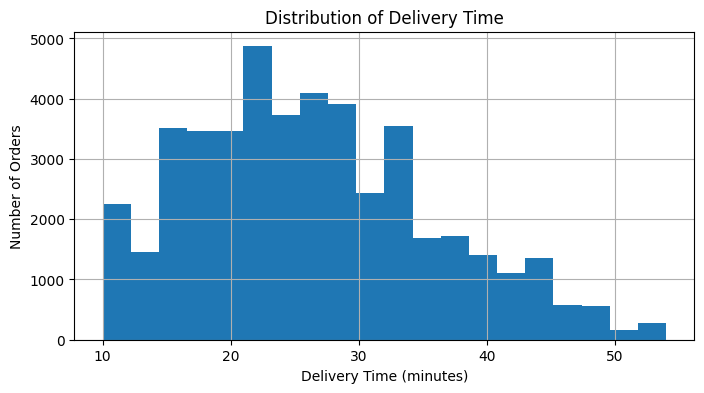

In [68]:
plt.figure(figsize=(8,4))
plt.hist(df['Time_taken (min)'], bins=20)
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Number of Orders')
plt.title('Distribution of Delivery Time')
plt.grid()
plt.show()

In [69]:
df['Delivery_person_Age'].describe()

count    45584.000000
mean        29.573776
std          5.637839
min         20.000000
25%         25.000000
50%         30.000000
75%         34.000000
max         39.000000
Name: Delivery_person_Age, dtype: float64

In [70]:
df['Delivery_person_Age'].value_counts().sort_index()

Delivery_person_Age
20.0    2136
21.0    2153
22.0    2194
23.0    2086
24.0    2210
25.0    2174
26.0    2159
27.0    2150
28.0    2179
29.0    2191
30.0    4171
31.0    2120
32.0    2201
33.0    2186
34.0    2165
35.0    2261
36.0    2260
37.0    2226
38.0    2218
39.0    2144
Name: count, dtype: int64

In [71]:
df['Delivery_person_Ratings'].describe()

count    45584.000000
mean         4.635034
std          0.324623
min          1.000000
25%          4.600000
50%          4.700000
75%          4.800000
max          5.000000
Name: Delivery_person_Ratings, dtype: float64

In [72]:
df['Delivery_person_Ratings'].value_counts().sort_index()

Delivery_person_Ratings
1.0      38
2.5      20
2.6      22
2.7      22
2.8      19
2.9      19
3.0       6
3.1      29
3.2      29
3.3      25
3.4      32
3.5     249
3.6     207
3.7     225
3.8     228
3.9     197
4.0    1077
4.1    1430
4.2    1418
4.3    1409
4.4    1360
4.5    3302
4.6    6938
4.7    9101
4.8    7146
4.9    7040
5.0    3996
Name: count, dtype: int64

In [73]:
df[['Distance_km', 'Time_taken (min)']].describe()

,Distance_km,Time_taken (min)
count,41513.000000,45584.000000
mean,9.719824,26.293963
std,5.602505,9.384298
min,1.465067,10.000000
25%,4.657655,19.000000
50%,9.193021,26.000000
75%,13.680920,32.000000
max,20.969489,54.000000


In [74]:
df[['Distance_km', 'Time_taken (min)']].corr() 

,Distance_km,Time_taken (min)
Distance_km,1.000000,0.321062
Time_taken (min),0.321062,1.000000


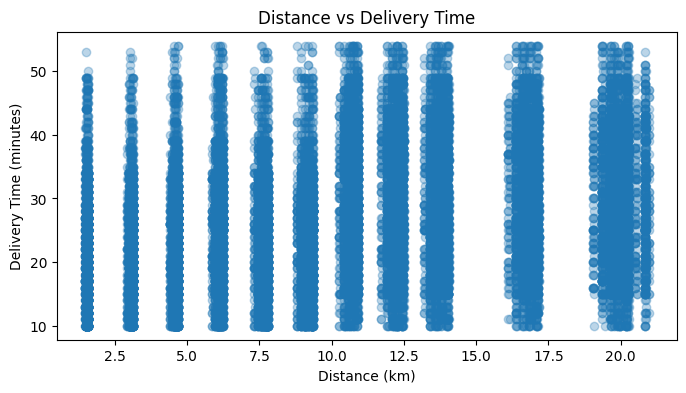

In [75]:
plt.figure(figsize=(8,4))
plt.scatter(
    df['Distance_km'],
    df['Time_taken (min)'],
    alpha=0.3
)
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (minutes)')
plt.title('Distance vs Delivery Time')
plt.show()

In [76]:
df.groupby('Road_traffic_density')['Time_taken (min)'].agg(
    ['count', 'mean', 'median']
).sort_values('mean')

,count,mean,median
Road_traffic_density,,,
Low,15476,21.266671,20.0
Unknown,601,26.542429,26.0
Medium,10945,26.699680,27.0
High,4423,27.240109,27.0
Jam,14139,31.176038,31.0


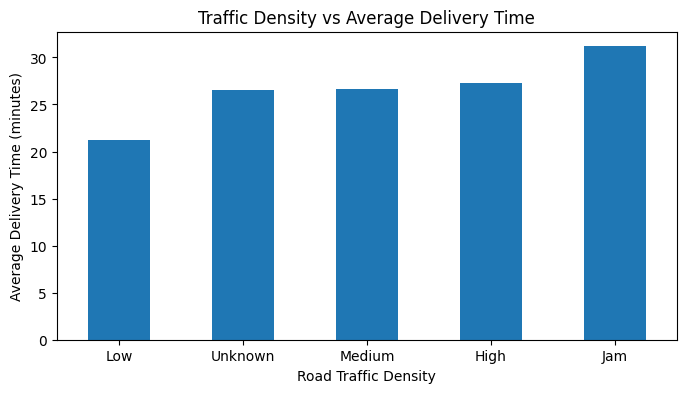

In [77]:
traffic_avg = df.groupby(
    'Road_traffic_density'
)['Time_taken (min)'].mean().sort_values()

traffic_avg.plot(kind='bar', figsize=(8, 4))

plt.xlabel('Road Traffic Density')
plt.ylabel('Average Delivery Time (minutes)')
plt.title('Traffic Density vs Average Delivery Time')
plt.xticks(rotation=0)

plt.show()

In [78]:
df.groupby('Weather_conditions')['Time_taken (min)'].agg(
    ['count', 'mean', 'median']
).sort_values('mean')

,count,mean,median
Weather_conditions,,,
Sunny,7282,21.856770,20.0
Stormy,7584,25.868803,26.0
Sandstorms,7494,25.875500,26.0
Windy,7422,26.118836,26.0
Unknown,616,26.545455,26.0
Fog,7653,28.914674,28.0
Cloudy,7533,28.917164,28.0


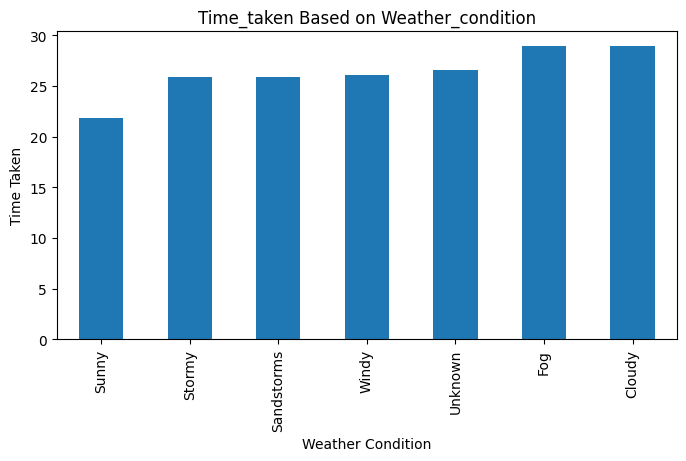

In [79]:
weather_avg=df.groupby('Weather_conditions')['Time_taken (min)'].mean().sort_values()
weather_avg.plot(kind='bar',figsize=(8,4))
plt.xlabel("Weather Condition")
plt.ylabel("Time Taken")
plt.title("Time_taken Based on Weather_condition")
plt.show()

In [80]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)',
       'Order_Time_Minutes', 'Order_Month', 'Order_DayOfWeek', 'Distance_km'],
      dtype='str')

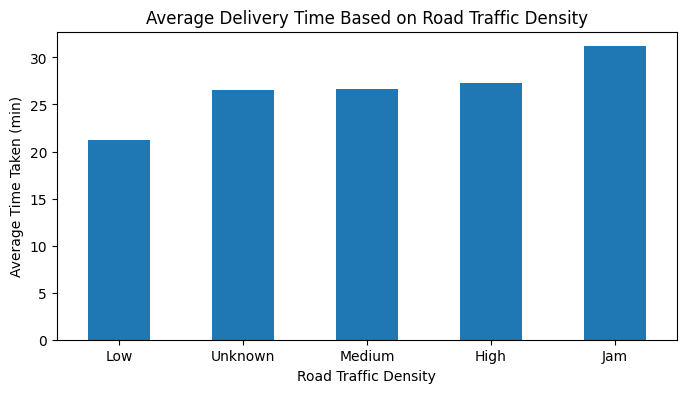

In [81]:
traffic_avg = df.groupby('Road_traffic_density')['Time_taken (min)'].mean().sort_values()

traffic_avg.plot(kind='bar', figsize=(8,4))
plt.xticks(rotation=0)
plt.xlabel("Road Traffic Density")
plt.ylabel("Average Time Taken (min)")
plt.title("Average Delivery Time Based on Road Traffic Density")
plt.show()

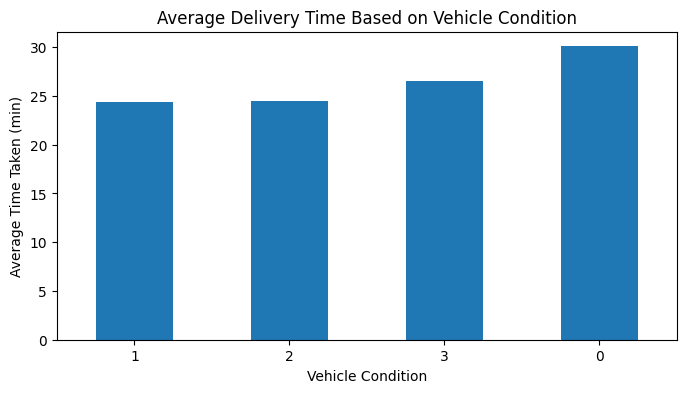

In [82]:
vehicle_avg = df.groupby('Vehicle_condition')['Time_taken (min)'].mean().sort_values()

vehicle_avg.plot(kind='bar', figsize=(8,4))
plt.xticks(rotation=0)
plt.xlabel("Vehicle Condition")
plt.ylabel("Average Time Taken (min)")
plt.title("Average Delivery Time Based on Vehicle Condition")
plt.show()

In [83]:
multiple_avg = df.groupby('multiple_deliveries')['Time_taken (min)'].mean().sort_values()

In [84]:
multiple_avg

multiple_deliveries
0.0    22.876188
1.0    26.715653
2.0    40.454912
3.0    47.819945
Name: Time_taken (min), dtype: float64

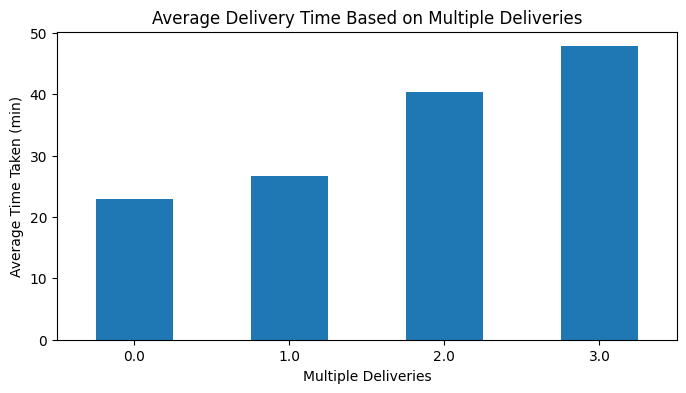

In [85]:
multiple_avg.plot(kind='bar', figsize=(8,4))
plt.xticks(rotation=0)
plt.xlabel("Multiple Deliveries")
plt.ylabel("Average Time Taken (min)")
plt.title("Average Delivery Time Based on Multiple Deliveries")
plt.show()

In [86]:
# delivery time when there are festivals
festival_avg = (
    df.groupby('Festival')['Time_taken (min)']
      .mean()
      .sort_values()
)

print(festival_avg)

Festival
Unknown    11.166667
No         25.984121
Yes        45.517857
Name: Time_taken (min), dtype: float64


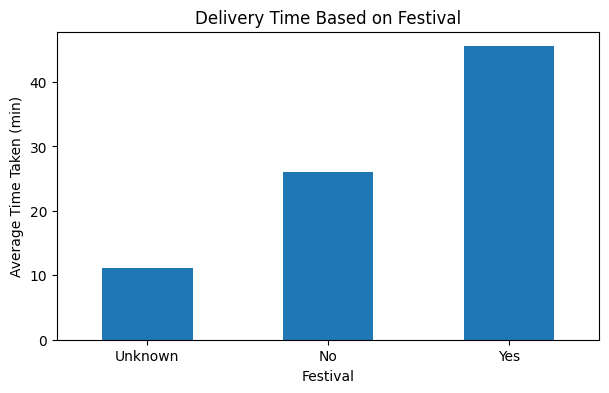

In [87]:
festival_avg.plot(
    kind='bar',
    figsize=(7,4)
)
plt.xticks(rotation=0)
plt.xlabel("Festival")
plt.ylabel("Average Time Taken (min)")
plt.title("Delivery Time Based on Festival")
plt.show()

In [88]:
city_avg = (
    df.groupby('City')['Time_taken (min)']
      .mean()
      .sort_values()
)
print(city_avg)

City
Unknown          22.058333
Urban            22.983322
Metropolitian    27.314460
Semi-Urban       49.731707
Name: Time_taken (min), dtype: float64


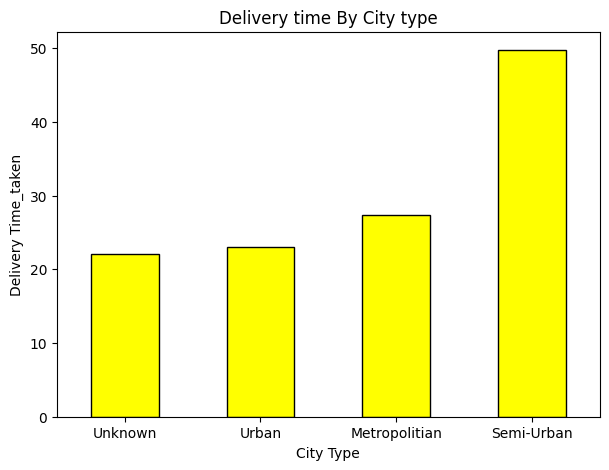

In [89]:
city_avg.plot(
    kind='bar',
    figsize=(7,5),
    color='yellow',
    edgecolor='black')
plt.xticks(rotation=0)

plt.xlabel("City Type")
plt.ylabel("Delivery Time_taken")
plt.title("Delivery time By City type")
plt.show()

In [90]:
order_type_avg=(
    df.groupby('Type_of_order')['Time_taken (min)'].mean().sort_values())
order_type_avg

Type_of_order
Drinks    26.187969
Buffet    26.283320
Snack     26.285603
Meal      26.417598
Name: Time_taken (min), dtype: float64

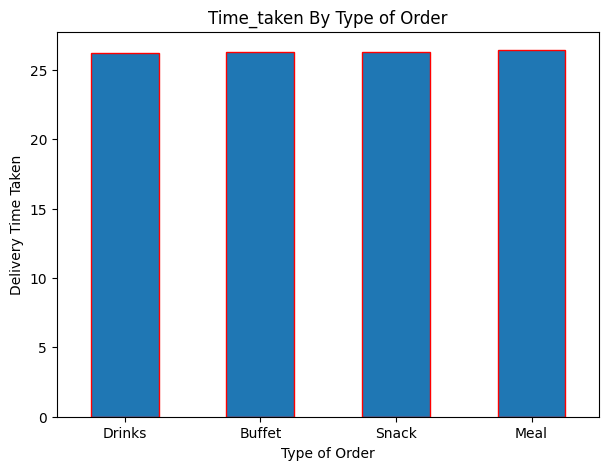

In [91]:
order_type_avg.plot(
    kind='bar',
    figsize=(7,5),
    edgecolor='red')
plt.xticks(rotation=0)
plt.xlabel('Type of Order')
plt.ylabel('Delivery Time Taken')
plt.title('Time_taken By Type of Order')
plt.show()

In [92]:
vehicle_avg=(
    df.groupby('Type_of_vehicle')['Time_taken (min)'].mean().sort_values()
)
vehicle_avg

Type_of_vehicle
electric_scooter    24.470110
scooter             24.478819
bicycle             26.426471
motorcycle          27.605774
Name: Time_taken (min), dtype: float64

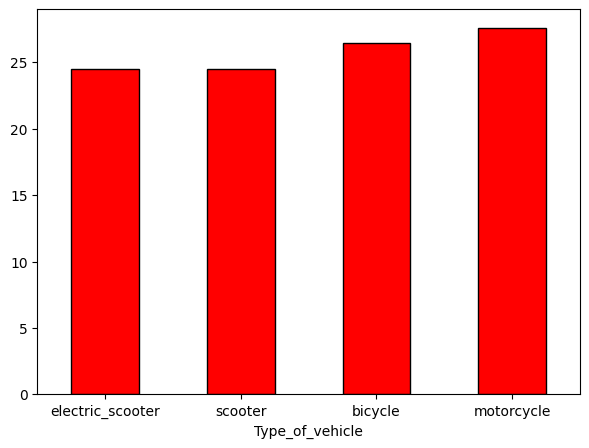

In [93]:
vehicle_avg.plot(
    kind='bar',
    figsize=(7,5),
    color='red',
    edgecolor='black'
)
plt.xticks(rotation=0)
plt.show()

In [94]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),Order_Time_Minutes,Order_Month,Order_DayOfWeek,Distance_km
0,0xcdcd,DEHRES17DEL01,36.0,4.2,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,1315.0,2,5,10.280582
1,0xd987,KOCRES16DEL01,21.0,4.7,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,895.0,2,6,6.242319
2,0x2784,PUNERES13DEL03,23.0,4.7,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,1050.0,3,4,13.787860
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,560.0,2,6,2.930258
4,0xdb64,KNPRES14DEL02,24.0,4.7,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,1190.0,2,0,19.396618


In [95]:
df[['Distance_km', 'Time_taken (min)']].corr()

,Distance_km,Time_taken (min)
Distance_km,1.000000,0.321062
Time_taken (min),0.321062,1.000000


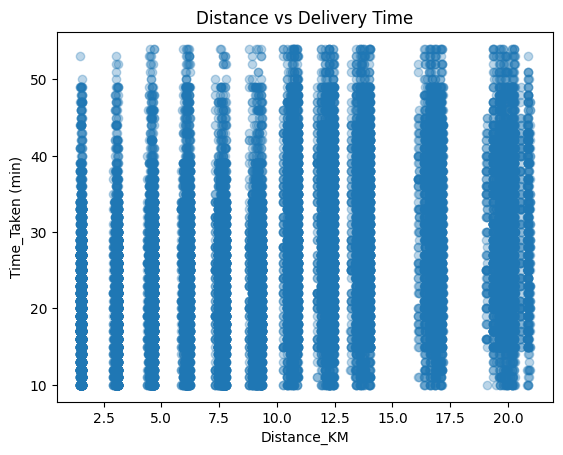

In [96]:
# Distance vs Delivery Time.
figsize=(7,5)
plt.scatter(df['Distance_km'],df['Time_taken (min)'],marker="o",alpha=0.3)
plt.xlabel("Distance_KM")
plt.ylabel("Time_Taken (min)")
plt.title("Distance vs Delivery Time")
plt.show()

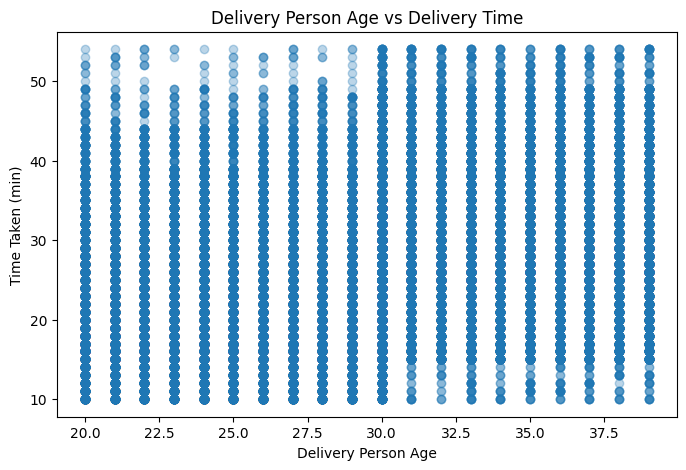

In [97]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['Delivery_person_Age'],
    df['Time_taken (min)'],
    alpha=0.3
)

plt.xlabel("Delivery Person Age")
plt.ylabel("Time Taken (min)")
plt.title("Delivery Person Age vs Delivery Time")

plt.show()

In [98]:
df[['Delivery_person_Age', 'Time_taken (min)']].corr()

,Delivery_person_Age,Time_taken (min)
Delivery_person_Age,1.000000,0.296906
Time_taken (min),0.296906,1.000000


In [99]:
df[['Delivery_person_Ratings', 'Time_taken (min)']].corr()

,Delivery_person_Ratings,Time_taken (min)
Delivery_person_Ratings,1.000000,-0.332955
Time_taken (min),-0.332955,1.000000


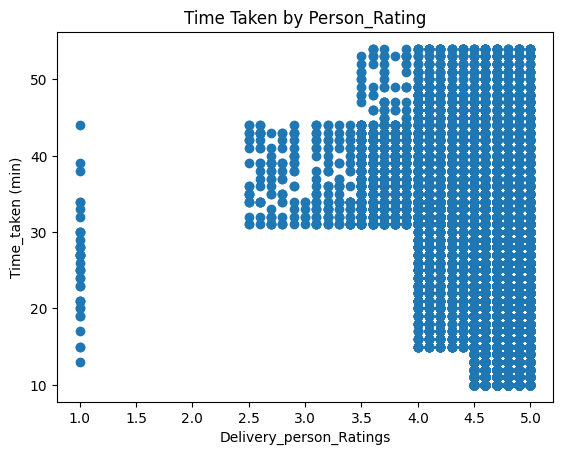

In [100]:
plt.scatter(df['Delivery_person_Ratings'],df['Time_taken (min)'])
plt.xlabel('Delivery_person_Ratings')
plt.ylabel('Time_taken (min)')
plt.title('Time Taken by Person_Rating')
plt.show()

In [101]:
df[['Order_Time_Minutes', 'Time_taken (min)']].corr()

,Order_Time_Minutes,Time_taken (min)
Order_Time_Minutes,1.000000,0.179861
Time_taken (min),0.179861,1.000000


In [102]:
df.groupby('Order_DayOfWeek')['Time_taken (min)'].mean().sort_values()

Order_DayOfWeek
3    25.183207
1    25.322874
5    26.099571
0    26.253142
6    26.399808
4    26.814741
2    27.759481
Name: Time_taken (min), dtype: float64

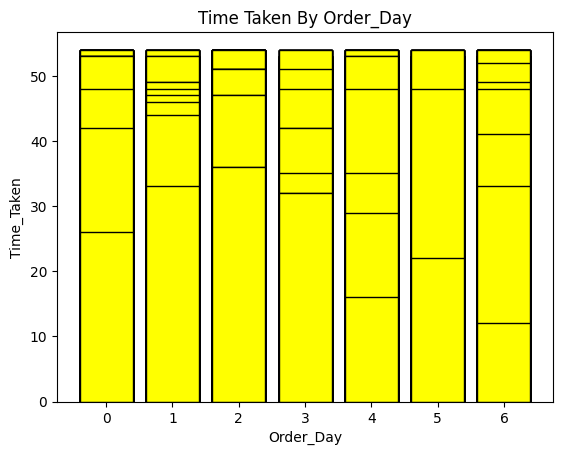

In [103]:
plt.bar(df['Order_DayOfWeek'],df['Time_taken (min)'],color='yellow',edgecolor='black')
plt.xlabel("Order_Day"),
plt.ylabel("Time_Taken"),
plt.title("Time Taken By Order_Day")
plt.show()

In [104]:
corr = df[
    [
        'Delivery_person_Age',
        'Delivery_person_Ratings',
        'Vehicle_condition',
        'multiple_deliveries',
        'Distance_km',
        'Order_Time_Minutes',
        'Order_Month',
        'Order_DayOfWeek',
        'Time_taken (min)'
    ]
].corr()

print(corr)

                         Delivery_person_Age  Delivery_person_Ratings  \
Delivery_person_Age                 1.000000                -0.111184   
Delivery_person_Ratings            -0.111184                 1.000000   
Vehicle_condition                   0.000206                 0.026809   
multiple_deliveries                 0.113079                -0.112573   
Distance_km                        -0.001072                -0.102805   
Order_Time_Minutes                  0.000343                -0.058372   
Order_Month                        -0.005820                -0.007345   
Order_DayOfWeek                     0.008184                -0.008164   
Time_taken (min)                    0.296906                -0.332955   

                         Vehicle_condition  multiple_deliveries  Distance_km  \
Delivery_person_Age               0.000206             0.113079    -0.001072   
Delivery_person_Ratings           0.026809            -0.112573    -0.102805   
Vehicle_condition            

In [105]:
import seaborn as sns


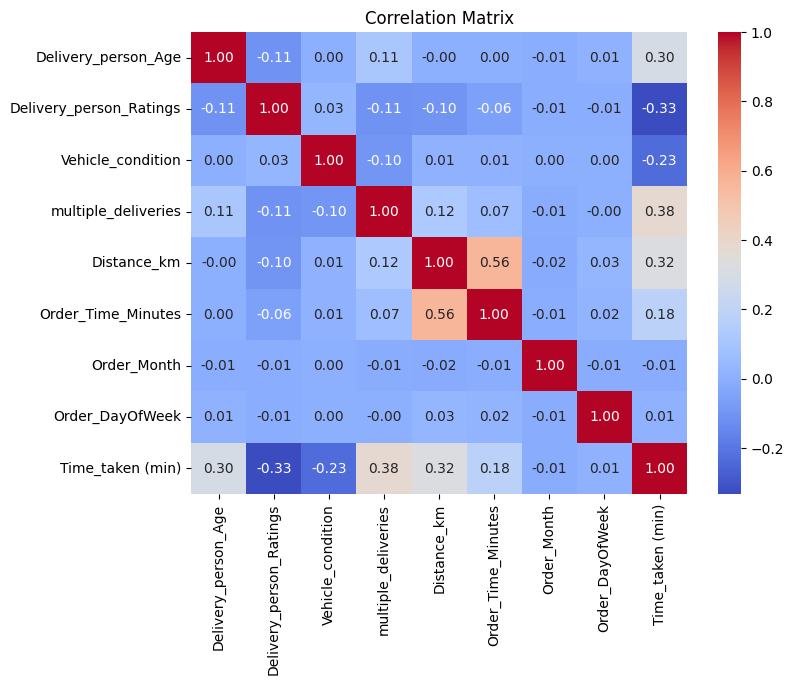

In [106]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix')
plt.show()

In [107]:
df[['Distance_km', 'Order_Time_Minutes']].describe()

,Distance_km,Order_Time_Minutes
count,41513.000000,45584.000000
mean,9.719824,1078.050193
std,5.602505,285.274719
min,1.465067,0.000000
25%,4.657655,950.000000
50%,9.193021,1155.000000
75%,13.680920,1290.000000
max,20.969489,1435.000000


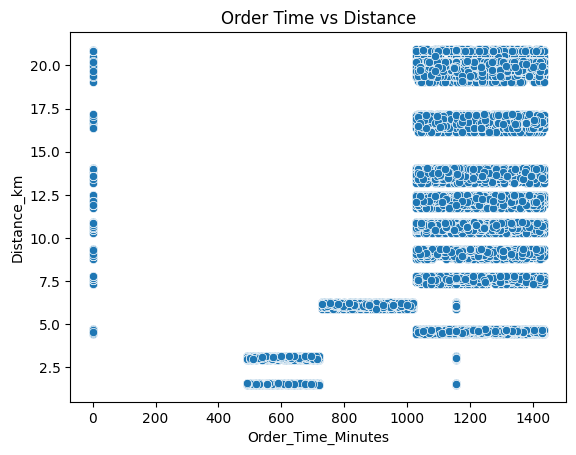

In [108]:
sns.scatterplot(
    data=df,
    x='Order_Time_Minutes',
    y='Distance_km'
)

plt.title('Order Time vs Distance')
plt.show()

In [109]:
df['Distance_km'].isna().sum()

np.int64(4071)

In [110]:
df[df['Distance_km'].isna()][
    ['Distance_km', 'City', 'Time_taken (min)']
].head(10)

,Distance_km,City,Time_taken (min)
24,NaN,Urban,35
43,NaN,Metropolitian,15
48,NaN,Semi-Urban,49
50,NaN,Metropolitian,30
58,NaN,Metropolitian,15
59,NaN,Urban,16
63,NaN,Urban,15
64,NaN,Metropolitian,17
67,NaN,Metropolitian,27
72,NaN,Metropolitian,25


In [111]:
df.groupby('City')['Distance_km'].agg(['count', 'median'])

,count,median
City,,
Metropolitian,31097,9.314907
Semi-Urban,147,12.464267
Unknown,1097,9.055361
Urban,9172,7.790160


In [112]:
df['Distance_km'] = df.groupby('City')['Distance_km'].transform(
    lambda x: x.fillna(x.median())
)

In [113]:
df['Distance_km'].isna().sum()

np.int64(0)

In [114]:
#now we are starting machine learning processing
X=df.drop(['Time_taken (min)'],axis=1)   # Other
Y=df['Time_taken (min)']   # target is the Time_taken column

In [115]:
print(X.shape)
print(Y.shape)

(45584, 16)
(45584,)


In [116]:
# Here we are importing the train_test_split to split the dataset
from sklearn.model_selection import train_test_split

In [117]:
# 20 percent data is splited for the training and testing
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.20,random_state=42)

In [118]:
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(36467, 16)
(9117, 16)
(36467,)
(9117,)


In [119]:
# Identifying numerical and categorical features
print(X_train.dtypes)

ID                             str
Delivery_person_ID             str
Delivery_person_Age        float64
Delivery_person_Ratings    float64
Weather_conditions             str
Road_traffic_density           str
Vehicle_condition            int64
Type_of_order                  str
Type_of_vehicle                str
multiple_deliveries        float64
Festival                       str
City                           str
Order_Time_Minutes         float64
Order_Month                  int32
Order_DayOfWeek              int32
Distance_km                float64
dtype: object


In [120]:
X_train = X_train.drop(['ID', 'Delivery_person_ID'], axis=1, errors='ignore')
X_test = X_test.drop(['ID', 'Delivery_person_ID'], axis=1, errors='ignore')

In [121]:
categorical_cols = [
    'Weather_conditions',
    'Road_traffic_density',
    'Type_of_order',
    'Type_of_vehicle',
    'Festival',
    'City'
]

In [122]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

In [123]:
X_train_encoded = encoder.fit_transform(X_train[categorical_cols])

In [124]:
X_test_encoded = encoder.transform(X_test[categorical_cols])

In [125]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(36467, 27)
(9117, 27)


In [126]:
numerical_cols = [
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'Vehicle_condition',
    'multiple_deliveries',
    'Order_Time_Minutes',
    'Order_Month',
    'Order_DayOfWeek',
    'Distance_km'
]

In [127]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[numerical_cols])
X_test_num = scaler.transform(X_test[numerical_cols])

In [128]:
X_train_num.shape
X_test_num.shape

(9117, 8)

In [129]:
X_train_final = np.hstack([X_train_num, X_train_encoded])
X_test_final = np.hstack([X_test_num, X_test_encoded])

In [130]:
print(X_train_final.shape)
print(X_test_final.shape)

(36467, 35)
(9117, 35)


In [131]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_final, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [132]:
predictions = model.predict(X_test_final)

In [133]:
predictions

array([33.44523329, 20.29193024, 22.60757708, ..., 35.53099834,
       26.30963486, 30.26711674], shape=(9117,))

In [134]:
from sklearn.metrics import mean_absolute_error,r2_score,mean_squared_error

In [135]:
mae=mean_absolute_error(Y_test,predictions)
r2=r2_score(Y_test,predictions)
mse=mean_squared_error(Y_test,predictions)
rmse=np.sqrt(mse)
print("mean absolute error:",mae)
print("r2 score:",r2)
print("RMSE:",rmse)

mean absolute error: 4.804782798881625
r2 score: 0.5847682531846541
RMSE: 6.0520940460630195


In [136]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_final, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [137]:
rf_predictions = rf_model.predict(X_test_final)
rf_predictions

array([34.17, 25.22, 15.41, ..., 39.71, 24.89, 29.75], shape=(9117,))

In [138]:
mae = mean_absolute_error(Y_test, rf_predictions)
r2 = r2_score(Y_test, rf_predictions)
rmse = np.sqrt(mean_squared_error(Y_test, rf_predictions))
print("MAE:", mae)
print("R2 Score:", r2)
print("RMSE:", rmse)

MAE: 3.2432214452853647
R2 Score: 0.8066050220462161
RMSE: 4.130313235421543


In [139]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestRegressor(random_state=42, n_jobs=-1)

params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=params,
    n_iter=10,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

search.fit(X_train_final, Y_train)

print("Best Parameters:", search.best_params_)
print("Best CV MAE:", -search.best_score_)

Best Parameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 30}
Best CV MAE: 3.2503130920266536


In [140]:
best_model = search.best_estimator_

tuned_predictions = best_model.predict(X_test_final)

from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
import numpy as np

print("MAE:", mean_absolute_error(Y_test, tuned_predictions))
print("R2 Score:", r2_score(Y_test, tuned_predictions))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, tuned_predictions)))

MAE: 3.2121449232496326
R2 Score: 0.8114916851251123
RMSE: 4.077797436226941


In [141]:
feature_names = numerical_cols + list(
    encoder.get_feature_names_out(categorical_cols)
)
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': best_model.feature_importances_
})
importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)
print(importance_df.head(10))

                      Feature  Importance
1     Delivery_person_Ratings    0.210165
3         multiple_deliveries    0.121079
7                 Distance_km    0.120338
17   Road_traffic_density_Low    0.115716
0         Delivery_person_Age    0.093199
2           Vehicle_condition    0.073667
12   Weather_conditions_Sunny    0.071040
9      Weather_conditions_Fog    0.037741
8   Weather_conditions_Cloudy    0.036919
4          Order_Time_Minutes    0.032210


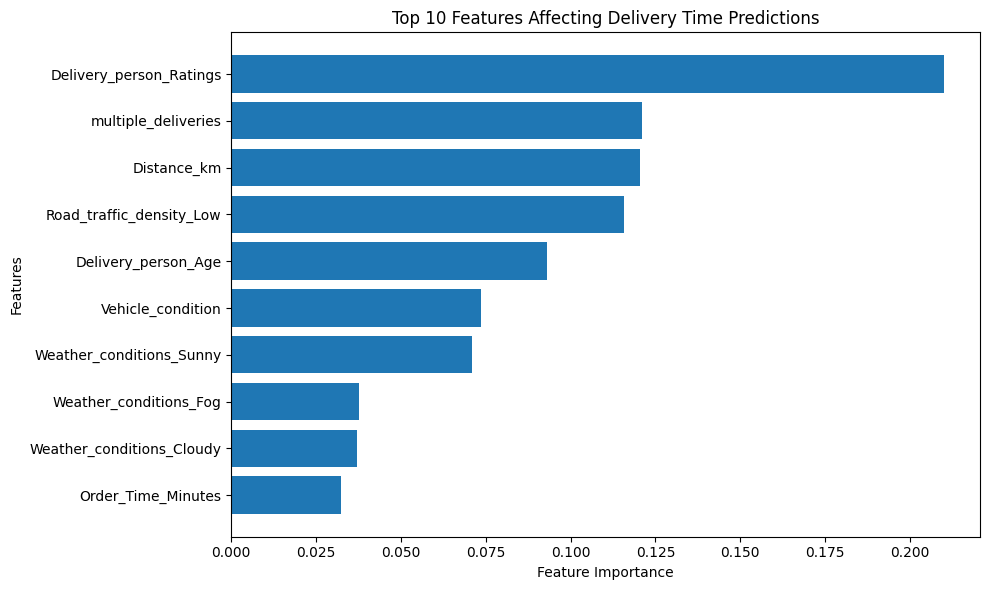

In [142]:
import matplotlib.pyplot as plt
top10 = importance_df.head(10).sort_values(
    by='Importance'
)
plt.figure(figsize=(10, 6))
plt.barh(top10['Feature'], top10['Importance'])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Features Affecting Delivery Time Predictions")
plt.tight_layout()
plt.show()

In [143]:
comparison = pd.DataFrame({
    'Actual Time': Y_test.values,
    'Predicted Time': tuned_predictions
})

comparison['Error'] = (
    comparison['Actual Time'] - comparison['Predicted Time']
)

print(comparison.head(10))

   Actual Time  Predicted Time     Error
0           33       34.538382 -1.538382
1           28       25.323335  2.676665
2           22       15.139061  6.860939
3           25       21.096740  3.903260
4           35       40.487142 -5.487142
5           27       27.117026 -0.117026
6           48       46.523753  1.476247
7           27       28.570405 -1.570405
8           24       20.772002  3.227998
9           18       23.840557 -5.840557


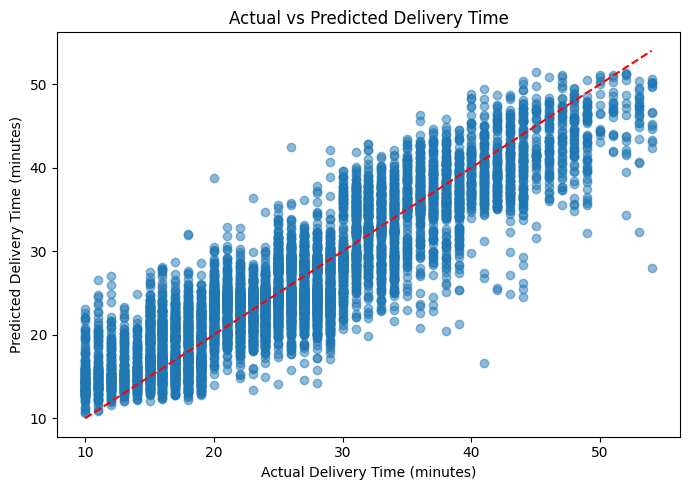

In [144]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(Y_test, tuned_predictions, alpha=0.5)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")

# Ideal predictions fall on this line
plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    'r--'
)

plt.tight_layout()
plt.show()

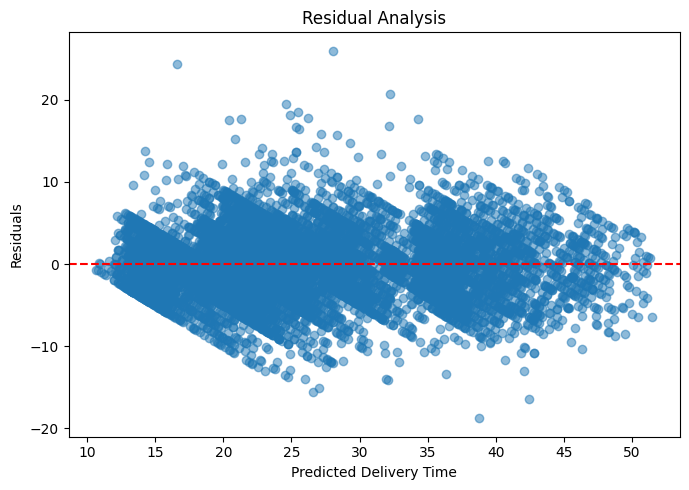

In [145]:
residuals = Y_test - tuned_predictions

plt.figure(figsize=(7, 5))
plt.scatter(tuned_predictions, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Delivery Time")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.tight_layout()
plt.show()

In [146]:
# 10 predictions with highest error
comparison['Absolute_Error'] = comparison['Error'].abs()
print(comparison.sort_values(
    by='Absolute_Error',
    ascending=False
).head(10))

      Actual Time  Predicted Time      Error  Absolute_Error
459            54       28.030086  25.969914       25.969914
768            41       16.608102  24.391898       24.391898
7139           53       32.266591  20.733409       20.733409
2558           44       24.568277  19.431723       19.431723
2069           20       38.777977 -18.777977       18.777977
493            44       25.492703  18.507297       18.507297
1719           43       24.886221  18.113779       18.113779
4534           44       26.201784  17.798216       17.798216
5220           39       21.294480  17.705520       17.705520
4565           52       34.322763  17.677237       17.677237


In [147]:
#This will show the input features for the 10 worst predictions.
error_indices = comparison.nlargest(10, 'Absolute_Error').index
X_test.iloc[error_indices]

,Delivery_person_Age,Delivery_person_Ratings,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Order_Time_Minutes,Order_Month,Order_DayOfWeek,Distance_km
3702,24.0,4.5,Sunny,Jam,0,Drinks,motorcycle,0.0,No,Metropolitian,1290.0,3,1,9.326616
15236,32.0,4.9,Fog,Medium,2,Drinks,scooter,1.0,No,Urban,1060.0,3,1,7.790160
30884,30.0,4.7,Sunny,High,0,Snack,motorcycle,1.0,No,Metropolitian,1155.0,3,3,6.116387
23460,30.0,4.7,Cloudy,Low,0,Drinks,motorcycle,1.0,No,Metropolitian,1155.0,3,1,9.314907
30529,30.0,4.7,Sandstorms,Medium,0,Snack,motorcycle,1.0,No,Metropolitian,1155.0,3,6,20.852514
44253,21.0,5.0,Cloudy,Medium,0,Buffet,motorcycle,1.0,No,Unknown,1065.0,3,3,9.055361
26603,30.0,4.6,Cloudy,Low,0,Drinks,motorcycle,1.0,No,Metropolitian,1425.0,3,6,9.314907
33582,30.0,4.7,Sandstorms,Jam,2,Snack,electric_scooter,0.0,No,Metropolitian,1155.0,3,2,12.257012
2762,21.0,4.9,Cloudy,Medium,1,Snack,motorcycle,1.0,No,Metropolitian,1030.0,4,2,9.314907
9545,30.0,4.7,Windy,Jam,0,Drinks,motorcycle,0.0,No,Metropolitian,1155.0,3,3,10.641572


In [148]:
abs_error = (Y_test.reset_index(drop=True) - tuned_predictions).abs()

print("Error > 5 minutes:", (abs_error > 5).sum())
print("Error > 10 minutes:", (abs_error > 10).sum())
print("Error > 15 minutes:", (abs_error > 15).sum())

print("Total predictions:", len(abs_error))

Error > 5 minutes: 1835
Error > 10 minutes: 156
Error > 15 minutes: 20
Total predictions: 9117


In [149]:
import joblib

joblib.dump(best_model, 'delivery_time_model.pkl')
joblib.dump(encoder, 'encoder.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model and preprocessing objects saved successfully!")

Model and preprocessing objects saved successfully!


In [150]:
import shap

explainer = shap.TreeExplainer(best_model)

print("SHAP Explainer created successfully!")

C:\Users\LENOVO\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP Explainer created successfully!


In [151]:
X_sample = X_test_final[:500]

shap_values = explainer.shap_values(X_sample)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (500, 35)


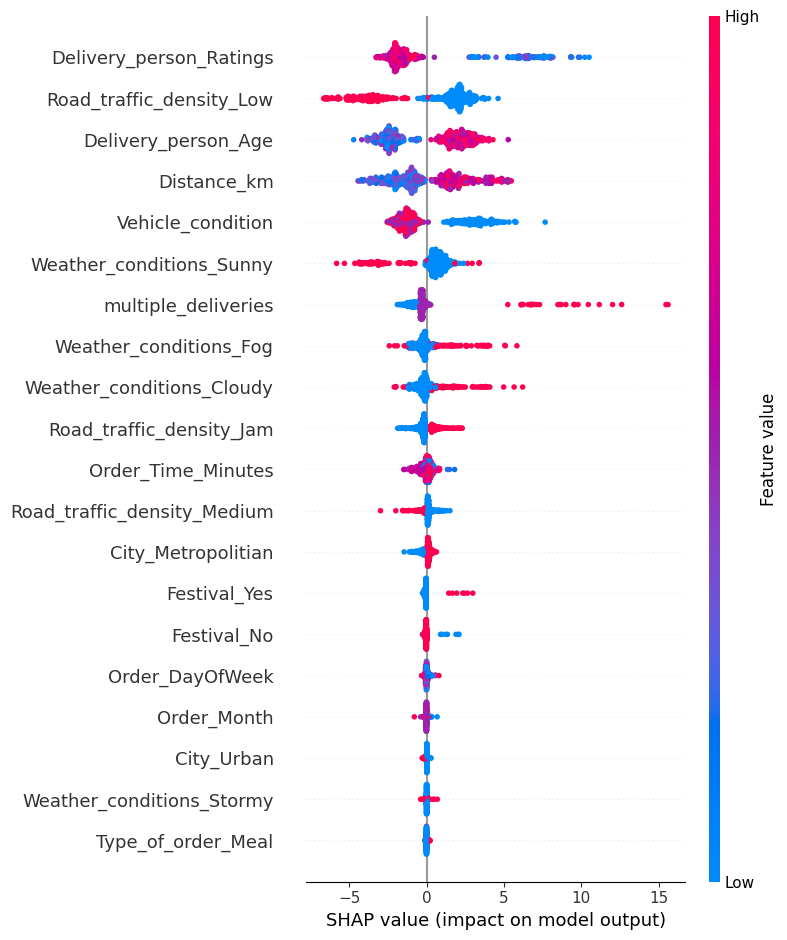

In [152]:
#This plot will show which features have the greatest influence on delivery-time predictions
# and whether they increase or decrease predicted time.
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_names
)

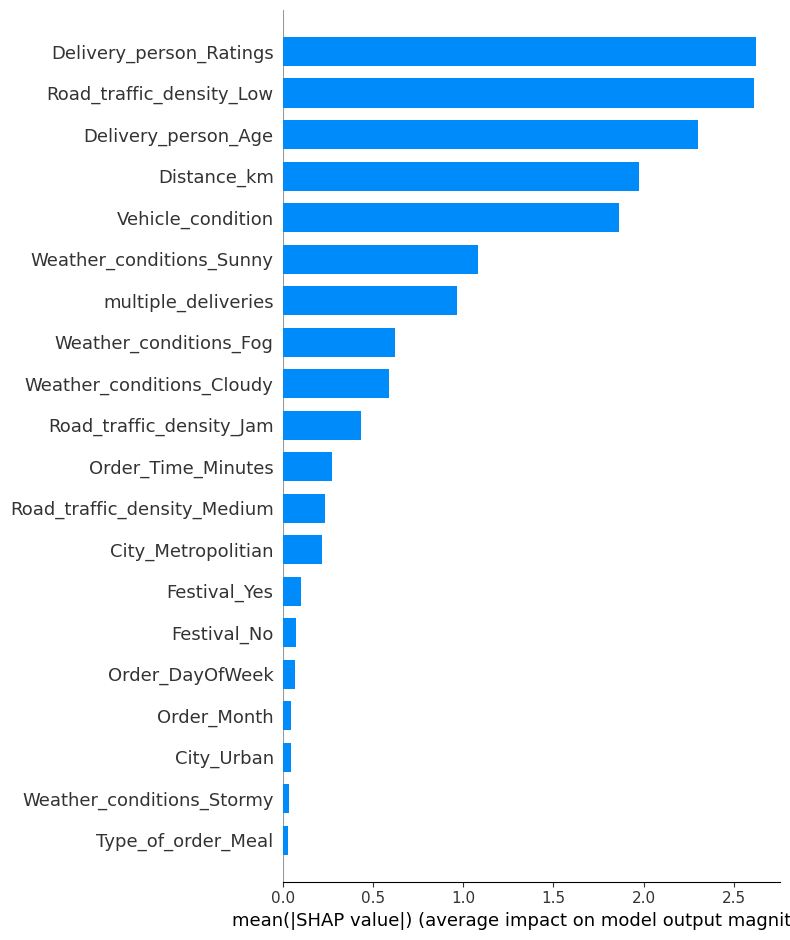

In [153]:
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_names,
    plot_type="bar"
)

In [154]:
shap.initjs()

shap.force_plot(
    explainer.expected_value,
    shap_values[0],
    X_sample[0],
    feature_names=feature_names
)

In [155]:
from sklearn.model_selection import cross_val_score
import numpy as np

cv_scores = cross_val_score(
    best_model,
    X_train_final,
    Y_train,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

mae_scores = -cv_scores

print("MAE for each fold:", mae_scores)
print("Average MAE:", np.mean(mae_scores))
print("Standard Deviation:", np.std(mae_scores))

MAE for each fold: [3.27090305 3.19434554 3.1994881  3.21815978 3.26343934]
Average MAE: 3.2292671634559076
Standard Deviation: 0.03203426610861208


In [156]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, KFold
from sklearn.base import clone
import numpy as np

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
    ('num', 'passthrough', numerical_cols)
])
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', clone(best_model))
])
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline,
    X_train,
    Y_train,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
mae_scores = -scores
print("Fold MAE:", mae_scores)
print("Average MAE:", np.mean(mae_scores))
print("Standard Deviation:", np.std(mae_scores))

Fold MAE: [3.2736635  3.25933903 3.21411704 3.19039471 3.20528835]
Average MAE: 3.2285605241299846
Standard Deviation: 0.03221314207841345


In [157]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [4.8048, 3.2121],
    'RMSE': [6.0521, 4.0778],
    'R2 Score': [0.5848, 0.8115]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.8048,6.0521,0.5848
1,Random Forest,3.2121,4.0778,0.8115
